In [1]:
import pandas as pd
print("pandas version:", pd.__version__)

pandas version: 3.0.6


In [2]:
import os
print(os.listdir("../Data/raw"))

['Thalassemia_Bangladesh_dataset.csv']


In [3]:
df = pd.read_csv("../Data/raw/"Thalassemia_Bangladesh_dataset.csv")
df.shape


SyntaxError: unterminated string literal (detected at line 1) (68204683.py, line 1)

In [4]:
df = pd.read_csv("../Data/raw/Thalassemia_Bangladesh_dataset.csv")
df.shape

(617, 24)

In [5]:
df.columns.tolist()

['Patient_ID',
 'Current_Age',
 'Gender',
 'Residence_Type',
 'Education_Level',
 'Monthly_Household_Income',
 'Travel_Time_to_Hospital (min)',
 'School/Work_Impact',
 'Age_at_Diagnosis',
 'Thalassemia_Type',
 'Splenectomy_Status',
 'Self-Reported_Comorbidities',
 'Pre-Transfusion_Hb (g/dL)',
 'Serum_Ferritin (ng/mL)',
 'MCV (fL)',
 'MCH (pg)',
 'RDW (%)',
 'Reticulocyte_Count (%)',
 'HbF_Percent (%)',
 'Transfusion_Frequency (units/month)',
 'Iron_Chelation_Therapy',
 'Chelation_Adherence',
 'BMI (kg/m²)',
 'Mental_Health_Status']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 617 entries, 0 to 616
Data columns (total 24 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Patient_ID                           617 non-null    int64  
 1   Current_Age                          617 non-null    int64  
 2   Gender                               617 non-null    str    
 3   Residence_Type                       617 non-null    str    
 4   Education_Level                      606 non-null    str    
 5   Monthly_Household_Income             617 non-null    str    
 6   Travel_Time_to_Hospital (min)        617 non-null    int64  
 7   School/Work_Impact                   431 non-null    str    
 8   Age_at_Diagnosis                     617 non-null    float64
 9   Thalassemia_Type                     617 non-null    str    
 10  Splenectomy_Status                   617 non-null    str    
 11  Self-Reported_Comorbidities          411 no

In [7]:
df.isnull().sum()

Patient_ID                               0
Current_Age                              0
Gender                                   0
Residence_Type                           0
Education_Level                         11
Monthly_Household_Income                 0
Travel_Time_to_Hospital (min)            0
School/Work_Impact                     186
Age_at_Diagnosis                         0
Thalassemia_Type                         0
Splenectomy_Status                       0
Self-Reported_Comorbidities            206
Pre-Transfusion_Hb (g/dL)                0
Serum_Ferritin (ng/mL)                   0
MCV (fL)                                 0
MCH (pg)                                 0
RDW (%)                                  0
Reticulocyte_Count (%)                   0
HbF_Percent (%)                          0
Transfusion_Frequency (units/month)      0
Iron_Chelation_Therapy                 170
Chelation_Adherence                    152
BMI (kg/m²)                              0
Mental_Heal

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Patient_ID,Current_Age,Travel_Time_to_Hospital (min),Age_at_Diagnosis,Pre-Transfusion_Hb (g/dL),Serum_Ferritin (ng/mL),MCV (fL),MCH (pg),RDW (%),Reticulocyte_Count (%),HbF_Percent (%),Transfusion_Frequency (units/month),BMI (kg/m²)
count,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.00000,617.000000,617.000000,617.000000
mean,309.000000,27.103728,51.166937,9.917666,10.581361,1519.241491,70.388979,22.453809,17.982172,4.85624,16.457050,2.269854,19.855105
std,178.256837,12.247804,98.558604,9.567876,3.307296,1603.474735,12.868380,6.935268,8.496065,4.26278,15.023854,2.584393,5.119023
min,1.000000,2.000000,6.000000,0.500000,3.600000,80.000000,43.000000,9.000000,5.000000,0.50000,1.000000,0.000000,7.100000
25%,155.000000,18.000000,18.000000,4.000000,7.000000,800.000000,63.000000,18.000000,13.000000,2.10000,6.000000,0.500000,14.600000
50%,309.000000,26.000000,30.000000,6.000000,10.700000,920.000000,69.000000,22.000000,16.000000,3.30000,12.000000,1.400000,20.900000
75%,463.000000,36.000000,68.000000,8.200000,12.800000,2900.000000,76.000000,27.000000,25.000000,8.50000,30.000000,3.500000,23.600000
max,617.000000,60.000000,1600.000000,35.000000,16.200000,10000.000000,93.000000,36.000000,42.000000,16.90000,64.000000,11.300000,29.300000


In [10]:
df["Thalassemia_Type"].value_counts()

Thalassemia_Type
Intermedia    302
Major         163
Minor         152
Name: count, dtype: int64

In [11]:
df_check = pd.read_csv("../Data/raw/Thalassemia_Bangladesh_dataset.csv", keep_default_na=False)

for col in ["Education_Level", "School/Work_Impact", "Self_Reported_Comorbidities",
            "Iron_Chelation_Therapy", "Chelation_Adherence"]:
    print(col)
    print(df_check[col].value_counts())
    print()

Education_Level
Education_Level
Graduate        286
Secondary       209
Primary          62
Postgraduate     46
None             11
Preschool         3
Name: count, dtype: int64

School/Work_Impact
School/Work_Impact
Moderate    186
None        186
Mild        171
High         69
Low           5
Name: count, dtype: int64

Self_Reported_Comorbidities


KeyError: 'Self_Reported_Comorbidities'

In [12]:
for col in df_check.columns:
    if any(key in col for key in ["Comorbid", "Chelation"]):
        print(col)
        print(df_check[col].value_counts())
        print()

Self-Reported_Comorbidities
Self-Reported_Comorbidities
                        206
Fatigue                  59
Bone pain                52
Weakness                 39
Joint pain               26
                       ... 
Headache                  1
Headache, Tiredness       1
Joint pain, weakness      1
Dizziness                 1
Fatigue, pale skin        1
Name: count, Length: 88, dtype: int64

Iron_Chelation_Therapy
Iron_Chelation_Therapy
DFX          202
DFP          191
None         170
DFX + DFP     53
DFX            1
Name: count, dtype: int64

Chelation_Adherence
Chelation_Adherence
Medium    241
High      196
N/A       152
Low        28
Name: count, dtype: int64



In [13]:
pd.crosstab(df_check["Iron_Chelation_Therapy"].str.strip(),
            df_check["Chelation_Adherence"])

Chelation_Adherence,High,Low,Medium,N/A
Iron_Chelation_Therapy,,,,
DFP,35,1,155,0
DFX,150,2,51,0
DFX + DFP,0,25,28,0
None,11,0,7,152


In [14]:
df_check["Iron_Chelation_Therapy"] = df_check["Iron_Chelation_Therapy"].str.strip()

conflict = df_check[(df_check["Iron_Chelation_Therapy"] == "None") &
                    (df_check["Chelation_Adherence"] != "N/A")]

print(len(conflict))
conflict[["Patient_ID", "Iron_Chelation_Therapy", "Chelation_Adherence",
          "Serum_Ferritin (ng/mL)", "Transfusion_Frequency (units/month)"]]

18


,Patient_ID,Iron_Chelation_Therapy,Chelation_Adherence,Serum_Ferritin (ng/mL),Transfusion_Frequency (units/month)
104,105,None,High,880,1.0
152,153,None,Medium,3000,4.2
172,173,None,High,910,1.0
218,219,None,High,900,1.3
256,257,None,High,910,1.0
332,333,None,High,900,1.5
338,339,None,High,940,1.6
366,367,None,Medium,3500,6.3
387,388,None,Medium,3500,6.8
411,412,None,Medium,3600,7.2


In [15]:
df = pd.read_csv("../Data/raw/Thalassemia_Bangladesh_dataset.csv", keep_default_na=False)

# Remove the stray space in "DFX "
df["Iron_Chelation_Therapy"] = df["Iron_Chelation_Therapy"].str.strip()

# Flag, don't delete, the patients whose therapy and adherence disagree
df["Chelation_Conflict"] = ((df["Iron_Chelation_Therapy"] == "None") &
                            (df["Chelation_Adherence"] != "N/A"))

print(df["Chelation_Conflict"].sum())
df["Iron_Chelation_Therapy"].value_counts()

18


Iron_Chelation_Therapy
DFX          203
DFP          191
None         170
DFX + DFP     53
Name: count, dtype: int64

In [16]:
# Cell A: extreme travel times
df.sort_values("Travel_Time_to_Hospital (min)", ascending=False)[
    ["Patient_ID", "Residence_Type", "Travel_Time_to_Hospital (min)"]
].head(10)

,Patient_ID,Residence_Type,Travel_Time_to_Hospital (min)
4,5,Urban,1600
472,473,Rural,1600
576,577,Rural,550
9,10,Urban,320
534,535,Rural,300
499,500,Rural,260
556,557,Urban,210
23,24,Urban,210
589,590,Rural,200
8,9,Urban,180


In [17]:
# Cell B: ferritin values stuck at exactly 10,000
(df["Serum_Ferritin (ng/mL)"] == 10000).sum()

np.int64(1)

In [18]:
# Cell C: diagnosed after current age? (should be 0)
(df["Age_at_Diagnosis"] > df["Current_Age"]).sum()

np.int64(0)

In [19]:
import numpy as np
import os

for col in df.columns:
    if pd.api.types.is_string_dtype(df[col]):
        df[col] = df[col].str.strip()

# Re-check the therapy/adherence conflict flag after tidying
df["Chelation_Conflict"] = (df["Iron_Chelation_Therapy"] == "None") & (df["Chelation_Adherence"] != "N/A")
df["Chelation_Conflict"].sum()

np.int64(18)

In [20]:
df["Travel_Time_Clean (min)"] = df["Travel_Time_to_Hospital (min)"]
df.loc[df["Travel_Time_to_Hospital (min)"] > 1000, "Travel_Time_Clean (min)"] = np.nan
df["Travel_Time_Clean (min)"].isnull().sum()

np.int64(2)

In [21]:
df["Ferritin_At_Cap"] = df["Serum_Ferritin (ng/mL)"] == 10000
df["Ferritin_At_Cap"].sum()

np.int64(1)

In [22]:
df["School/Work_Impact"] = df["School/Work_Impact"].replace({"Low": "Mild"})
df["School/Work_Impact"].value_counts()

School/Work_Impact
Moderate    186
None        186
Mild        176
High         69
Name: count, dtype: int64

In [23]:
comorb_col = [c for c in df.columns if "Comorbid" in c][0]
df["Has_Reported_Symptoms"] = df[comorb_col] != ""
df["Has_Reported_Symptoms"].value_counts()

Has_Reported_Symptoms
True     411
False    206
Name: count, dtype: int64

In [24]:
os.makedirs("../Data/processed", exist_ok=True)
df.to_csv("../Data/processed/clean.csv", index=False)
df.shape

(617, 28)

In [25]:
df["Age_Group"] = pd.cut(df["Current_Age"],
                         bins=[0, 12, 18, 30, 100],
                         labels=["Child (2-12)", "Adolescent (13-18)",
                                 "Young adult (19-30)", "Adult (31+)"])
df["Age_Group"].value_counts().sort_index()

Age_Group
Child (2-12)            76
Adolescent (13-18)      91
Young adult (19-30)    218
Adult (31+)            232
Name: count, dtype: int64

In [26]:
df["Years_Since_Diagnosis"] = df["Current_Age"] - df["Age_at_Diagnosis"]
df["Years_Since_Diagnosis"].describe()

count    617.000000
mean      17.186062
std        8.625626
min        1.500000
25%       10.400000
50%       15.800000
75%       22.000000
max       46.100000
Name: Years_Since_Diagnosis, dtype: float64

In [27]:
df["Ferritin_Risk"] = pd.cut(df["Serum_Ferritin (ng/mL)"],
                             bins=[0, 1000, 2500, float("inf")],
                             labels=["Controlled (<=1000)", "Elevated (1001-2500)", "High (>2500)"])
df["Ferritin_Risk"].value_counts().sort_index()

Ferritin_Risk
Controlled (<=1000)     445
Elevated (1001-2500)     14
High (>2500)            158
Name: count, dtype: int64

In [28]:
for col in ["Monthly_Household_Income", "Mental_Health_Status",
            "Chelation_Adherence", "Splenectomy_Status",
            "Residence_Type", "Gender"]:
    print(df[col].value_counts())
    print()

Monthly_Household_Income
25,000    114
20,000    106
30,000     70
15,000     62
65,000     48
60,000     43
70,000     34
45,000     33
40,000     28
35,000     20
55,000     16
50,000     16
10,000     12
75,000      6
80,000      3
20,500      2
85,000      2
36,500      1
30,500      1
Name: count, dtype: int64

Mental_Health_Status
Bad     400
Good    217
Name: count, dtype: int64

Chelation_Adherence
Medium    241
High      196
N/A       152
Low        28
Name: count, dtype: int64

Splenectomy_Status
No     352
Yes    265
Name: count, dtype: int64

Residence_Type
Urban    359
Rural    258
Name: count, dtype: int64

Gender
Male      326
Female    291
Name: count, dtype: int64



In [29]:
df.to_csv("../Data/processed/clean.csv", index=False)
df.shape

(617, 31)

In [30]:
df["Income_Monthly"] = df["Monthly_Household_Income"].str.replace(",", "").astype(int)
df["Income_Monthly"].describe()

count      617.000000
mean     35904.376013
std      18709.951090
min      10000.000000
25%      20000.000000
50%      30000.000000
75%      50000.000000
max      85000.000000
Name: Income_Monthly, dtype: float64

In [31]:
df["Income_Band"] = pd.cut(df["Income_Monthly"],
                           bins=[0, 20000, 30000, 50000, 1000000],
                           labels=["Low (<=20k)", "Lower-middle (20k-30k)",
                                   "Middle (30k-50k)", "Higher (>50k)"])
df["Income_Band"].value_counts().sort_index()

Income_Band
Low (<=20k)               180
Lower-middle (20k-30k)    186
Middle (30k-50k)           99
Higher (>50k)             152
Name: count, dtype: int64

In [32]:
df["Income_Band"] = pd.cut(df["Income_Monthly"],
                           bins=[0, 20000, 30000, 50000, 1000000],
                           labels=["Low (<=20k)", "Lower-middle (20k-30k)",
                                   "Middle (30k-50k)", "Higher (>50k)"])
df["Income_Band"].value_counts().sort_index()

Income_Band
Low (<=20k)               180
Lower-middle (20k-30k)    186
Middle (30k-50k)           99
Higher (>50k)             152
Name: count, dtype: int64

In [33]:
pd.crosstab(df["Thalassemia_Type"], df["Ferritin_Risk"])

Ferritin_Risk,Controlled (<=1000),Elevated (1001-2500),High (>2500)
Thalassemia_Type,,,
Intermedia,293,9,0
Major,0,5,158
Minor,152,0,0


In [34]:
df.to_csv("../Data/processed/clean.csv", index=False)
df.shape

(617, 33)

In [35]:
df = pd.read_csv("../Data/processed/clean.csv", keep_default_na=False)

In [36]:
pd.crosstab(df["Thalassemia_Type"], df["Iron_Chelation_Therapy"])

Iron_Chelation_Therapy,DFP,DFX,DFX + DFP,None
Thalassemia_Type,,,,
Intermedia,134,156,0,12
Major,57,47,53,6
Minor,0,0,0,152


In [37]:
df.groupby(["Thalassemia_Type", "Iron_Chelation_Therapy"])["Serum_Ferritin (ng/mL)"].agg(["count", "median"])

count  median
Thalassemia_Type Iron_Chelation_Therapy               
Intermedia       DFP                       134   930.0
                 DFX                       156   905.0
                 None                       12   910.0
Major            DFP                        57  3750.0
                 DFX                        47  3200.0
                 DFX + DFP                  53  3700.0
                 None                        6  3550.0
Minor            None                      152   125.0

Matplotlib is building the font cache; this may take a moment.


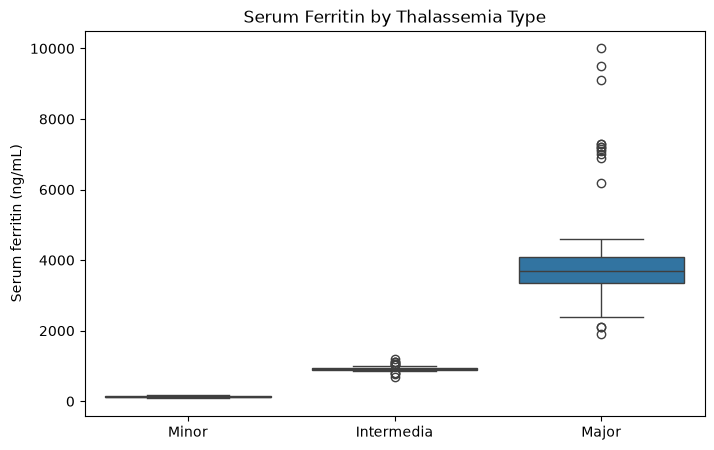

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Thalassemia_Type", y="Serum_Ferritin (ng/mL)",
            order=["Minor", "Intermedia", "Major"])
plt.title("Serum Ferritin by Thalassemia Type")
plt.ylabel("Serum ferritin (ng/mL)")
plt.xlabel("")
plt.savefig("../Images/ferritin_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

In [39]:
df = pd.read_csv("../Data/processed/clean.csv", keep_default_na=False)

In [40]:
none_nonminor = (df["Iron_Chelation_Therapy"] == "None") & (df["Thalassemia_Type"] != "Minor")
(none_nonminor == df["Chelation_Conflict"]).all()


np.True_

In [41]:
df.groupby("Thalassemia_Type")["Serum_Ferritin (ng/mL)"].describe()

,count,mean,std,min,25%,50%,75%,max
Thalassemia_Type,,,,,,,,
Intermedia,302.0,920.149007,48.086933,700.0,890.0,920.0,940.0,1200.0
Major,163.0,3927.300613,1204.187683,1900.0,3350.0,3700.0,4100.0,10000.0
Minor,152.0,127.217105,24.023696,80.0,110.0,125.0,145.0,190.0


In [42]:
treated = df[df["Iron_Chelation_Therapy"] != "None"]
treated.groupby(["Thalassemia_Type", "Chelation_Adherence"])["Serum_Ferritin (ng/mL)"].agg(["count", "median"])

count  median
Thalassemia_Type Chelation_Adherence               
Intermedia       High                   171   910.0
                 Medium                 119   925.0
Major            High                    14  2850.0
                 Low                     28  4450.0
                 Medium                 115  3700.0

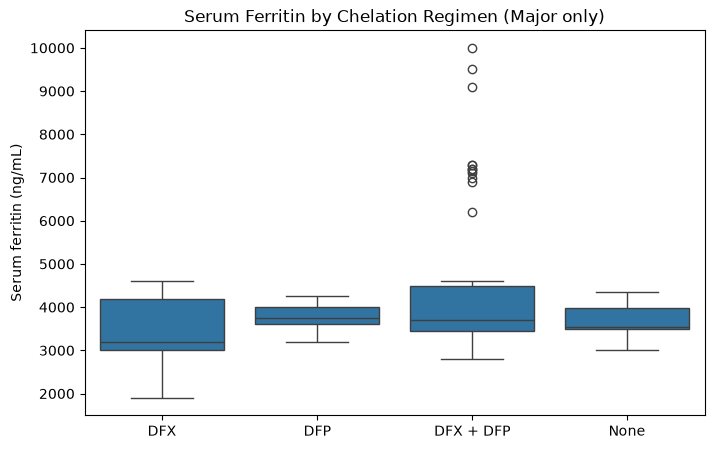

In [43]:
major = df[df["Thalassemia_Type"] == "Major"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=major, x="Iron_Chelation_Therapy", y="Serum_Ferritin (ng/mL)",
            order=["DFX", "DFP", "DFX + DFP", "None"])
plt.title("Serum Ferritin by Chelation Regimen (Major only)")
plt.xlabel("")
plt.ylabel("Serum ferritin (ng/mL)")
plt.savefig("../Images/ferritin_major_by_regimen.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
none_nonminor = (df["Iron_Chelation_Therapy"] == "None") & (df["Thalassemia_Type"] != "Minor")
(none_nonminor == df["Chelation_Conflict"]).all()

np.True_

In [45]:
major = df[df["Thalassemia_Type"] == "Major"]
pd.crosstab(major["Iron_Chelation_Therapy"], major["Chelation_Adherence"])

Chelation_Adherence,High,Low,Medium
Iron_Chelation_Therapy,,,
DFP,0,1,56
DFX,14,2,31
DFX + DFP,0,25,28
None,0,0,6


In [46]:
from scipy import stats

mt = df[(df["Thalassemia_Type"] == "Major") & (df["Iron_Chelation_Therapy"] != "None")].copy()
groups = [g["Serum_Ferritin (ng/mL)"].values for _, g in mt.groupby("Chelation_Adherence")]
stats.kruskal(*groups)

KruskalResult(statistic=np.float64(43.96015605517921), pvalue=np.float64(2.845597042565879e-10))

In [47]:
mt["adh_score"] = mt["Chelation_Adherence"].map({"Low": 1, "Medium": 2, "High": 3})
stats.spearmanr(mt["adh_score"], mt["Serum_Ferritin (ng/mL)"])

SignificanceResult(statistic=np.float64(-0.49664481914790326), pvalue=np.float64(3.706213246870929e-11))

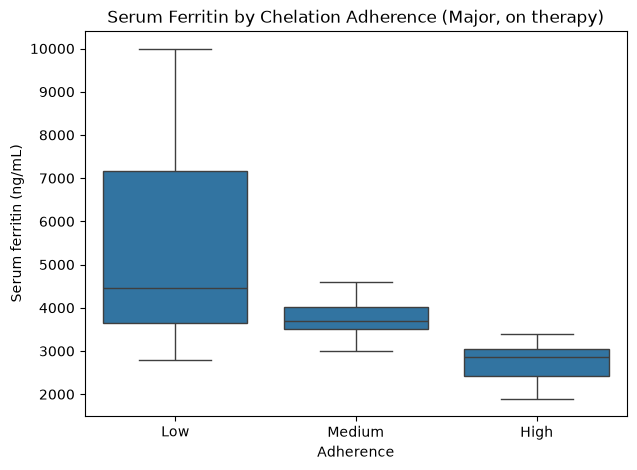

In [48]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=mt, x="Chelation_Adherence", y="Serum_Ferritin (ng/mL)",
            order=["Low", "Medium", "High"])
plt.title("Serum Ferritin by Chelation Adherence (Major, on therapy)")
plt.xlabel("Adherence")
plt.ylabel("Serum ferritin (ng/mL)")
plt.savefig("../Images/ferritin_by_adherence.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
dfx = mt[(mt["Iron_Chelation_Therapy"] == "DFX") &
         (mt["Chelation_Adherence"].isin(["High", "Medium"]))]
high = dfx[dfx["Chelation_Adherence"] == "High"]["Serum_Ferritin (ng/mL)"]
med = dfx[dfx["Chelation_Adherence"] == "Medium"]["Serum_Ferritin (ng/mL)"]
print(len(high), len(med), high.median(), med.median())
stats.mannwhitneyu(high, med)

14 31 2850.0 4100.0


MannwhitneyuResult(statistic=np.float64(31.5), pvalue=np.float64(5.313524206849447e-06))

In [50]:
med_adh = mt[mt["Chelation_Adherence"] == "Medium"]
print(med_adh.groupby("Iron_Chelation_Therapy")["Serum_Ferritin (ng/mL)"].agg(["count", "median"]))
groups = [g["Serum_Ferritin (ng/mL)"].values for _, g in med_adh.groupby("Iron_Chelation_Therapy")]
stats.kruskal(*groups)

                        count  median
Iron_Chelation_Therapy               
DFP                        56  3775.0
DFX                        31  4100.0
DFX + DFP                  28  3575.0


KruskalResult(statistic=np.float64(13.113827654009679), pvalue=np.float64(0.0014202621283081877))

In [51]:
mt = df[(df["Thalassemia_Type"] == "Major") & (df["Iron_Chelation_Therapy"] != "None")].copy()

In [52]:
from itertools import combinations

med_adh = mt[mt["Chelation_Adherence"] == "Medium"]
pairs = list(combinations(["DFX", "DFP", "DFX + DFP"], 2))

for a, b in pairs:
    x = med_adh[med_adh["Iron_Chelation_Therapy"] == a]["Serum_Ferritin (ng/mL)"]
    y = med_adh[med_adh["Iron_Chelation_Therapy"] == b]["Serum_Ferritin (ng/mL)"]
    p = stats.mannwhitneyu(x, y).pvalue
    print(f"{a} vs {b}: p = {p:.4f}  (significant if below {0.05/len(pairs):.4f})")

DFX vs DFP: p = 0.6474  (significant if below 0.0167)
DFX vs DFX + DFP: p = 0.3300  (significant if below 0.0167)
DFP vs DFX + DFP: p = 0.0000  (significant if below 0.0167)


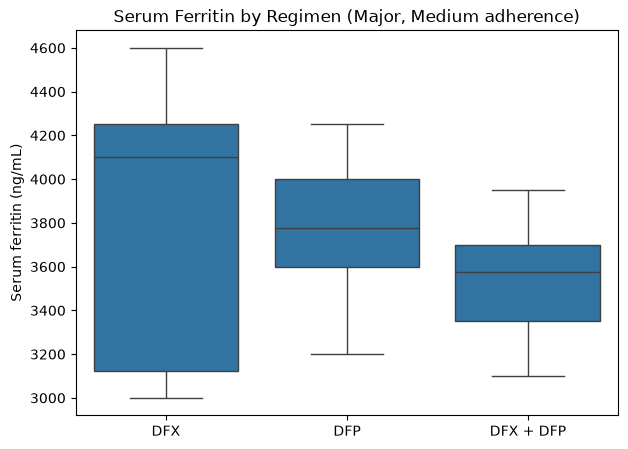

In [53]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=med_adh, x="Iron_Chelation_Therapy", y="Serum_Ferritin (ng/mL)",
            order=["DFX", "DFP", "DFX + DFP"])
plt.title("Serum Ferritin by Regimen (Major, Medium adherence)")
plt.xlabel("")
plt.ylabel("Serum ferritin (ng/mL)")
plt.savefig("../Images/ferritin_medium_adherence_by_regimen.png", dpi=150, bbox_inches="tight")
plt.show()

In [54]:
import os
os.makedirs("../Excel", exist_ok=True)

mt = df[(df["Thalassemia_Type"] == "Major") & (df["Iron_Chelation_Therapy"] != "None")].copy()

by_type = df.groupby("Thalassemia_Type").agg(
    Patients=("Patient_ID", "count"),
    Median_Ferritin=("Serum_Ferritin (ng/mL)", "median"),
    Median_Hb=("Pre-Transfusion_Hb (g/dL)", "median"),
    Avg_Transfusion_Units_per_Month=("Transfusion_Frequency (units/month)", "mean"),
).round(1)

adherence = mt.groupby("Chelation_Adherence")["Serum_Ferritin (ng/mL)"].agg(["count", "median"])

mental_by_income = (pd.crosstab(df["Income_Band"], df["Mental_Health_Status"], normalize="index") * 100).round(1)

with pd.ExcelWriter("../Excel/thalassemia_summary.xlsx") as writer:
    df.to_excel(writer, sheet_name="Clean_Data", index=False)
    by_type.to_excel(writer, sheet_name="By_Type")
    adherence.to_excel(writer, sheet_name="Adherence_Major")
    mental_by_income.to_excel(writer, sheet_name="Mental_by_Income")

print("Saved")

Saved


In [55]:
df

,Patient_ID,Current_Age,Gender,Residence_Type,Education_Level,Monthly_Household_Income,Travel_Time_to_Hospital (min),School/Work_Impact,Age_at_Diagnosis,Thalassemia_Type,...,Mental_Health_Status,Chelation_Conflict,Travel_Time_Clean (min),Ferritin_At_Cap,Has_Reported_Symptoms,Age_Group,Years_Since_Diagnosis,Ferritin_Risk,Income_Monthly,Income_Band
0,1,4,Male,Rural,None,"25,000",90,High,1.5,Major,...,Bad,False,90.0,False,True,Child (2-12),2.5,High (>2500),25000,Lower-middle (20k-30k)
1,2,12,Female,Urban,Primary,"25,000",40,Moderate,3.0,Major,...,Bad,False,40.0,False,True,Child (2-12),9.0,Elevated (1001-2500),25000,Lower-middle (20k-30k)
2,3,17,Male,Urban,Secondary,"30,000",25,Mild,6.0,Intermedia,...,Good,False,25.0,False,False,Adolescent (13-18),11.0,Elevated (1001-2500),30000,Lower-middle (20k-30k)
3,4,25,Female,Urban,Graduate,"45,000",10,None,8.0,Intermedia,...,Good,False,10.0,False,True,Young adult (19-30),17.0,Controlled (<=1000),45000,Middle (30k-50k)
4,5,28,Male,Urban,Graduate,"55,000",1600,None,20.0,Minor,...,Good,False,,False,False,Young adult (19-30),8.0,Controlled (<=1000),55000,Higher (>50k)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
612,613,41,Male,Urban,Graduate,"25,000",20,Mild,5.1,Intermedia,...,Bad,True,20.0,False,True,Adult (31+),35.9,Controlled (<=1000),25000,Lower-middle (20k-30k)
613,614,47,Female,Urban,Graduate,"25,000",45,Moderate,7.5,Intermedia,...,Bad,False,45.0,False,True,Adult (31+),39.5,Controlled (<=1000),25000,Lower-middle (20k-30k)
614,615,24,Female,Urban,Secondary,"20,000",20,Moderate,2.1,Major,...,Bad,False,20.0,False,True,Young adult (19-30),21.9,High (>2500),20000,Low (<=20k)
615,616,35,Male,Rural,Secondary,"15,000",60,Moderate,4.2,Major,...,Bad,False,60.0,False,True,Adult (31+),30.8,High (>2500),15000,Low (<=20k)


In [56]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Income_Band"], df["Mental_Health_Status"])
chi2, p, dof, expected = chi2_contingency(table)
n = table.values.sum()
cramers_v = (chi2 / (n * (min(table.shape) - 1))) ** 0.5

print(table)
print("chi2 =", round(chi2, 1), "| p =", p, "| dof =", dof)
print("Cramer's V =", round(cramers_v, 2))
print("Smallest expected count:", expected.min().round(1))

Mental_Health_Status    Bad  Good
Income_Band                      
Higher (>50k)            11   141
Low (<=20k)             179     1
Lower-middle (20k-30k)  153    33
Middle (30k-50k)         57    42
chi2 = 342.8 | p = 5.470642486062549e-74 | dof = 3
Cramer's V = 0.75
Smallest expected count: 34.8


In [57]:
for t, g in df.groupby("Thalassemia_Type"):
    print(t, "(n =", len(g), ")")
    print((pd.crosstab(g["Income_Band"], g["Mental_Health_Status"], normalize="index") * 100).round(1))
    print()

Intermedia (n = 302 )
Mental_Health_Status      Bad  Good
Income_Band                        
Higher (>50k)           100.0   0.0
Low (<=20k)              98.6   1.4
Lower-middle (20k-30k)   77.2  22.8
Middle (30k-50k)         57.5  42.5

Major (n = 163 )
Mental_Health_Status      Bad
Income_Band                  
Low (<=20k)             100.0
Lower-middle (20k-30k)  100.0
Middle (30k-50k)        100.0

Minor (n = 152 )
Mental_Health_Status   Good
Income_Band                
Higher (>50k)         100.0
Middle (30k-50k)      100.0



In [58]:
(pd.crosstab(df["Education_Level"], df["Mental_Health_Status"], normalize="index") * 100).round(1)

Mental_Health_Status,Bad,Good
Education_Level,,
Graduate,60.1,39.9
None,100.0,0.0
Postgraduate,2.2,97.8
Preschool,100.0,0.0
Primary,85.5,14.5
Secondary,76.6,23.4


In [59]:
pd.crosstab(df["Thalassemia_Type"], df["Mental_Health_Status"], margins=True)

Mental_Health_Status,Bad,Good,All
Thalassemia_Type,,,
Intermedia,237,65,302
Major,163,0,163
Minor,0,152,152
All,400,217,617


In [60]:
pd.crosstab(df["Thalassemia_Type"], df["Income_Band"])

Income_Band,Higher (>50k),Low (<=20k),Lower-middle (20k-30k),Middle (30k-50k)
Thalassemia_Type,,,,
Intermedia,11,73,145,73
Major,0,107,41,15
Minor,141,0,0,11


In [61]:
inter = df[df["Thalassemia_Type"] == "Intermedia"]
t = pd.crosstab(inter["Income_Band"], inter["Mental_Health_Status"])
print(t)
chi2, p, dof, exp = chi2_contingency(t)
v = (chi2 / (t.values.sum() * (min(t.shape) - 1))) ** 0.5
print("chi2 =", round(chi2, 1), "| p =", p, "| V =", round(v, 2), "| min expected =", exp.min().round(1))

Mental_Health_Status    Bad  Good
Income_Band                      
Higher (>50k)            11     0
Low (<=20k)              72     1
Lower-middle (20k-30k)  112    33
Middle (30k-50k)         42    31
chi2 = 39.7 | p = 1.2596195484586576e-08 | V = 0.36 | min expected = 2.4


In [62]:
inter3 = inter[inter["Income_Band"].astype(str) != "Higher (>50k)"]
t3 = pd.crosstab(inter3["Income_Band"].astype(str), inter3["Mental_Health_Status"])
chi2, p, dof, exp = chi2_contingency(t3)
v = (chi2 / (t3.values.sum() * (min(t3.shape) - 1))) ** 0.5
print(t3)
print("chi2 =", round(chi2, 1), "| p =", p, "| V =", round(v, 2), "| min expected =", exp.min().round(1))

Mental_Health_Status    Bad  Good
Income_Band                      
Low (<=20k)              72     1
Lower-middle (20k-30k)  112    33
Middle (30k-50k)         42    31
chi2 = 35.6 | p = 1.8935597770173004e-08 | V = 0.35 | min expected = 16.3


                  count  mean  std  min  25%  50%  75%   max
Thalassemia_Type                                            
Intermedia        302.0   1.3  0.3  0.4  1.1  1.4  1.6   2.4
Major             163.0   6.1  1.9  2.5  4.5  6.2  7.6  11.3
Minor             152.0   0.0  0.0  0.0  0.0  0.0  0.0   0.0


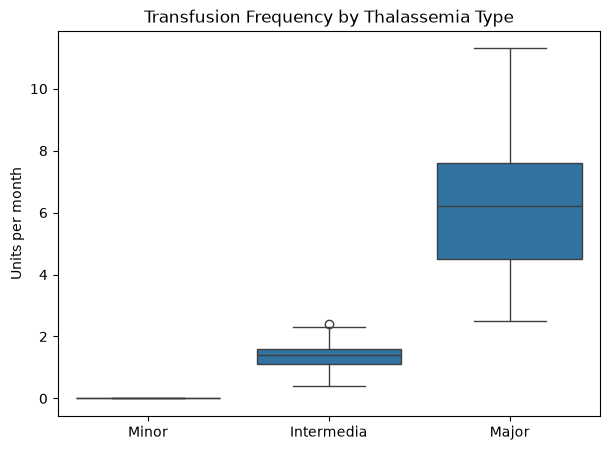

In [63]:
print(df.groupby("Thalassemia_Type")["Transfusion_Frequency (units/month)"].describe().round(1))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Thalassemia_Type", y="Transfusion_Frequency (units/month)",
            order=["Minor", "Intermedia", "Major"])
plt.title("Transfusion Frequency by Thalassemia Type")
plt.xlabel("")
plt.ylabel("Units per month")
plt.savefig("../Images/transfusion_by_type.png", dpi=150, bbox_inches="tight")
plt.show()